# 1· Retrain the DeepLabV3+ model

Inputs: 400×400 PNG false-colour tiles, channels **B8/NIR, B4/Red, B3/Green**, pixel values 0–255; matched binary mask PNGs (0/1 or 0/255). The model applies ResNet preprocessing internally. Do not apply an additional PyTorch/ImageNet normalization.

## Import Libs

In [2]:
!pip install albumentations -q

In [3]:
from pathlib import Path
import os, sys, json

In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
import albumentations as A

In [5]:
import warnings
warnings.filterwarnings("ignore")

import json, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2

import tensorflow as tf
from tensorflow.keras import Input, Model, Sequential
from tensorflow.keras.layers import (Layer, Conv2D, BatchNormalization, ReLU, AveragePooling2D,
                                     UpSampling2D, Concatenate, Dropout, Activation)
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

import albumentations as A
from sklearn.model_selection import GroupShuffleSplit
from skimage.filters import threshold_otsu

## Utils

In [6]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import tensorflow as tf
from tensorflow.keras import Input, Model, Sequential
from tensorflow.keras.layers import (Layer, Conv2D, BatchNormalization, ReLU,
    AveragePooling2D, UpSampling2D, Concatenate, Dropout, Activation)
from tensorflow.keras.applications import ResNet50
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit

In [7]:
def configure_gpu():
    for device in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(device, True)
    return tf.config.list_physical_devices("GPU")

In [8]:
class LakeDataset:
    """One original plus configurable augmentation views per source image.
    """
    def __init__(self, img_paths, mask_paths, transform=None,
                 augmented_copies_per_image=0):
        assert len(img_paths) == len(mask_paths) and len(img_paths) > 0
        assert all(i.stem == m.stem for i, m in zip(img_paths, mask_paths))
        if (isinstance(augmented_copies_per_image, (bool, np.bool_))
                or not isinstance(augmented_copies_per_image, (int, np.integer))
                or augmented_copies_per_image < 0):
            raise ValueError("augmented_copies_per_image must be a nonnegative integer")
        if augmented_copies_per_image and transform is None:
            raise ValueError("Extra augmentation views require a transform")
        self.img_paths, self.mask_paths, self.transform = list(img_paths), list(mask_paths), transform
        self.augmented_copies_per_image = int(augmented_copies_per_image)
        self.views_per_image = 1 + self.augmented_copies_per_image

    def __len__(self):
        return len(self.img_paths) * self.views_per_image

    def __getitem__(self, i):
        if i < 0:
            i += len(self)
        if not 0 <= i < len(self):
            raise IndexError("Dataset index out of range")
        image_index, view_index = divmod(i, self.views_per_image)
        img = load_image(self.img_paths[image_index])
        mask = load_mask(self.mask_paths[image_index])
        if view_index > 0:
            out = self.transform(image=img, mask=mask)
            img, mask = out['image'], out['mask']
        return img.astype(np.float32), mask[..., None].astype(np.float32)

In [9]:
# class LakeDataset:
#     """Returns (image HxWx3 float32 in [0,255], mask HxWx1 float32 in {0,1}).
#     Normalisation happens inside the model, so no mean/std here."""
#     def __init__(self, img_paths, mask_paths, transform=None):
#         assert len(img_paths) == len(mask_paths) and len(img_paths) > 0
#         assert all(i.stem == m.stem for i, m in zip(img_paths, mask_paths))
#         self.img_paths, self.mask_paths, self.transform = list(img_paths), list(mask_paths), transform

#     def __len__(self):
#         return len(self.img_paths)

#     def __getitem__(self, i):
#         img, mask = load_image(self.img_paths[i]), load_mask(self.mask_paths[i])
#         if self.transform:
#             out = self.transform(image=img, mask=mask)
#             img, mask = out['image'], out['mask']
#         return img.astype(np.float32), mask[..., None].astype(np.float32)

In [10]:
class SegSequence(tf.keras.utils.PyDataset):
    """Re-iterable Keras data source (replaces the one-shot generator)."""
    def __init__(self, dataset, batch_size, shuffle=False, **kwargs):
        super().__init__(**kwargs)
        self.ds, self.bs, self.shuffle = dataset, batch_size, shuffle
        self.order = np.arange(len(dataset))
        if shuffle: np.random.shuffle(self.order)

    def __len__(self):
        return int(np.ceil(len(self.ds) / self.bs))

    def __getitem__(self, i):
        items = [self.ds[j] for j in self.order[i * self.bs:(i + 1) * self.bs]]
        return np.stack([x for x, _ in items]), np.stack([y for _, y in items])

    def on_epoch_end(self):
        if self.shuffle: np.random.shuffle(self.order)

In [11]:
def load_image(path):
    return np.array(Image.open(path).convert('RGB'))

In [12]:
def load_mask(path):
    # Binarize: any non-zero pixel = water
    mask = np.array(Image.open(path).convert('L'))
    return (mask > (0 if mask.max() <= 1 else 127)).astype(np.float32)

In [13]:
reg = tf.keras.utils.register_keras_serializable(package='glof')

@reg
class ResNetPreprocess(Layer):
    """Keras ResNet50 ImageNet weights expect BGR, mean-subtracted, 0-255 input."""
    def call(self, x):
        x = tf.reverse(x, axis=[-1])
        return x - tf.constant([103.939, 116.779, 123.68], dtype=x.dtype)

@reg
class ConvBlock(Layer):
    def __init__(self, filters=256, kernel_size=3, dilation_rate=1, **kwargs):
        super().__init__(**kwargs)
        self.filters, self.kernel_size, self.dilation_rate = filters, kernel_size, dilation_rate
        self.net = Sequential([
            Conv2D(filters, kernel_size=kernel_size, padding='same', dilation_rate=dilation_rate,
                   use_bias=False, kernel_initializer='he_normal'),
            BatchNormalization(),
            ReLU(),
        ])

    def call(self, X):
        return self.net(X)

    def get_config(self):
        return {**super().get_config(), 'filters': self.filters,
                'kernel_size': self.kernel_size, 'dilation_rate': self.dilation_rate}

In [14]:
def AtrousSpatialPyramidPooling(X, rates=(2, 4, 6), filters=256):
    # 400px input at output stride 16 -> 25x25 map, so the usual (6,12,18) rates would mostly
    # sample zero padding. Use rates that fit the feature-map size.
    _, H, W, _ = X.shape
    image_pool = AveragePooling2D(pool_size=(H, W), name='ASPP-AvgPool')(X)
    image_pool = ConvBlock(filters, kernel_size=1, name='ASPP-ImagePool-CB')(image_pool)
    image_pool = UpSampling2D(size=(H, W), name='ASPP-ImagePool-UpSample')(image_pool)
    branches = [image_pool, ConvBlock(filters, kernel_size=1, name='ASPP-CB-1')(X)]
    branches += [ConvBlock(filters, kernel_size=3, dilation_rate=r, name=f'ASPP-CB-{r}')(X) for r in rates]
    out = ConvBlock(filters, kernel_size=1, name='ASPP-Net')(Concatenate(name='ASPP-Combine')(branches))
    return Dropout(0.1, name='ASPP-Dropout')(out)

In [15]:
def build_deeplabv3plus(image_size=400, aspp_rates=(2, 4, 6), weights='imagenet'):
    if image_size % 16:
        raise ValueError("image_size must be divisible by 16")
    inp = Input(shape=(image_size, image_size, 3), name='InputLayer')
    x = ResNetPreprocess(name='ResNetPreprocess')(inp)

    backbone = ResNet50(include_top=False, weights=weights, input_shape=(image_size, image_size, 3))
    feat_model = Model(backbone.input,
                       [backbone.get_layer('conv2_block3_out').output,   # stride 4  (low-level)
                        backbone.get_layer('conv4_block6_out').output],  # stride 16 (high-level)
                       name='resnet50_features')
    low, high = feat_model(x)

    aspp = AtrousSpatialPyramidPooling(high, rates=aspp_rates)
    aspp = UpSampling2D(size=(low.shape[1] // aspp.shape[1], low.shape[2] // aspp.shape[2]),
                        interpolation='bilinear', name='ASPP-Upsample')(aspp)
    low = ConvBlock(48, kernel_size=1, name='LLF-ConvBlock')(low)

    f = Concatenate(axis=-1, name='Combine-LLF-ASPP')([aspp, low])
    f = ConvBlock(name='Top-ConvBlock-1')(f)
    f = ConvBlock(name='Top-ConvBlock-2')(f)

    logits = Conv2D(1, kernel_size=1, use_bias=True, name='Logits')(f)          # bias lets it learn the class prior
    logits = UpSampling2D(size=(image_size // logits.shape[1], image_size // logits.shape[2]),
                          interpolation='bilinear', name='Top-UpSample')(logits)
    out = Activation('sigmoid', name='OutputMask')(logits)
    return Model(inp, out, name='DeepLabV3Plus-ResNet50'), feat_model

## Loss Functions & Metrics

In [16]:
@reg
def dice_loss(y_true, y_pred, smooth=1.0):
    y_true = tf.cast(y_true, y_pred.dtype)
    inter = tf.reduce_sum(y_true * y_pred, axis=[1, 2, 3])
    denom = tf.reduce_sum(y_true, axis=[1, 2, 3]) + tf.reduce_sum(y_pred, axis=[1, 2, 3])
    return 1.0 - tf.reduce_mean((2.0 * inter + smooth) / (denom + smooth))

In [17]:
@reg
def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + dice_loss(y_true, y_pred)

In [18]:
@reg
def dice_coefficient(y_true, y_pred, smooth=1.0):
    """Hard (thresholded @0.5) Dice."""
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred > 0.5, tf.float32)
    inter = tf.reduce_sum(y_true * y_pred)
    return (2.0 * inter + smooth) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

In [19]:
def make_metrics():
    # Stateful, dataset-level, thresholded at 0.5 (accuracy dropped: ~87% of pixels are background)
    return [tf.keras.metrics.BinaryIoU(target_class_ids=[1], threshold=0.5, name='iou'),
            tf.keras.metrics.Precision(thresholds=0.5, name='precision'),
            tf.keras.metrics.Recall(thresholds=0.5, name='recall'),
            dice_coefficient]

In [20]:
def compute_ndwi(img):
    """NDWI from a false-colour image (channels: NIR, Red, Green)."""
    img = img.astype(np.float32) / 255.0
    nir, green = img[:, :, 0], img[:, :, 2]
    return (green - nir) / (green + nir + 1e-8)

In [21]:
def ndwi_to_mask(ndwi, threshold=0.0):
    return (ndwi > threshold).astype(np.float32)

In [22]:
def compute_metrics(pred, target):
    """Per-image IoU / Precision / Recall / F1 on HARD (binary) masks."""
    pred, target = pred.flatten().astype(np.float64), target.flatten().astype(np.float64)
    tp = (pred * target).sum()
    fp = (pred * (1 - target)).sum()
    fn = ((1 - pred) * target).sum()
    precision = tp / (tp + fp + 1e-8)
    recall    = tp / (tp + fn + 1e-8)
    iou       = tp / (tp + fp + fn + 1e-8)
    f1        = 2 * precision * recall / (precision + recall + 1e-8)
    return {'IoU': iou, 'Precision': precision, 'Recall': recall, 'F1': f1}

In [23]:
def dataset_split(data_dir, output_dir, seed=42, INDEPENDENT_TILES = True):
    # data_dir, output_dir = Path(data_dir), Path(output_dir)
    images = {p.stem:p for p in (data_dir/"data/images").glob("*.png")}
    masks = {p.stem:p for p in (data_dir/"data/masks").glob("*.png")}
    # print(data_dir)
    # print(images)
    # print(masks)
    if not images or images.keys() != masks.keys():
        raise ValueError("Need matched images/*.png and masks/*.png with identical stems")
    paths = [images[k] for k in sorted(images)]
    for p in paths:
        if load_image(p).shape != (400,400,3) or load_mask(masks[p.stem]).shape != (400,400):
            raise ValueError(f"Expected 400x400 image/mask: {p.name}")
    ### Train Test Split
    idx = np.arange(len(paths))
    # train, other = next(GroupShuffleSplit(n_splits=1, test_size=.30, random_state=seed).split(idx))
    # val, test = next(GroupShuffleSplit(n_splits=1, test_size=.50, random_state=seed).split(other))
    train, other = next(ShuffleSplit(n_splits=1, test_size=0.30, random_state=seed).split(idx))
    val, test = next(ShuffleSplit(n_splits=1, test_size=0.50, random_state=seed).split(other))
    splits = {"train":train, "validation":other[val], "test":other[test]}
    output_dir.mkdir(parents=True, exist_ok=True)
    # rows = [{"filename":paths[i].name, "group_id":groups[i], "split":name}
    #         for name, indexes in splits.items() for i in indexes]
    # pd.DataFrame(rows).to_csv(output_dir/"segmentation_split.csv",index=False)
    return {name:([paths[i] for i in indexes], [masks[paths[i].stem] for i in indexes])
            for name,indexes in splits.items()}

## Load Dataset

In [24]:
# from glofwatch.segmentation import (configure_gpu,dataset_split,LakeDataset,SegSequence,
#     build_deeplabv3plus,bce_dice_loss,make_metrics,compute_metrics,compute_ndwi)
# from glofwatch.config import atomic_json,sha256_file

In [25]:
print("TensorFlow:",tf.__version__,"| GPUs:",configure_gpu())

### Params
SEED = 42
IMAGE_SIZE = 400
tf.keras.utils.set_random_seed(SEED)
BATCH_SIZE = 16
### Phase 1 Training
HEAD_EPOCHS = 5
### Phase 2 Training
FINE_TUNE_EPOCHS = 50
AUGMENTED_COPIES_PER_IMAGE = 1

DATA_DIR   = Path('/content/drive/MyDrive/Codes/')
IMG_DIR    = DATA_DIR / 'data'
# MASK_DIR   = DATA_DIR / 'data'
MODEL_DIR  = Path(f'{DATA_DIR}/models')
MODEL_DIR.mkdir(parents=True, exist_ok=True)


# def dataset_split(data_dir, output_dir, seed=42, INDEPENDENT_TILES = True):
splits = dataset_split(DATA_DIR, IMG_DIR ,seed=SEED)
print({name:len(paths[0]) for name,paths in splits.items()})

TensorFlow: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
{'train': 287, 'validation': 61, 'test': 62}


### Apply data augmentations

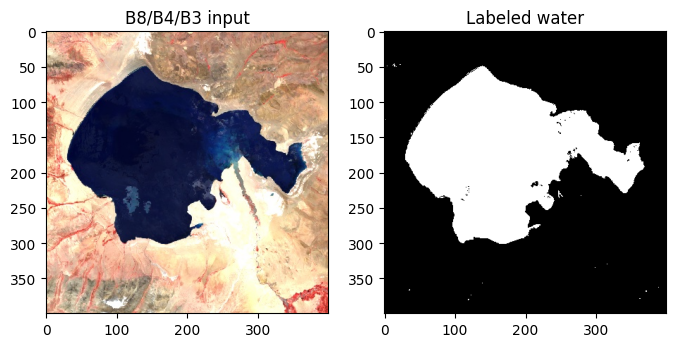

In [26]:
augmentation = A.Compose([A.HorizontalFlip(p=.5),A.VerticalFlip(p=.5),A.RandomRotate90(p=.5),
                          A.RandomBrightnessContrast(brightness_limit=.1,contrast_limit=.1,p=.3)])
# datasets = {name:LakeDataset(*paths,transform=augmentation if name=="train" else None)
#             for name,paths in splits.items()}

datasets = {
    name: LakeDataset(*paths, transform=augmentation if name == "train" else None,
        augmented_copies_per_image=( AUGMENTED_COPIES_PER_IMAGE if name == "train" else 0 )) for name, paths in splits.items() }

sequences = {name:SegSequence(dataset,BATCH_SIZE,shuffle=name=="train",workers=1)
             for name,dataset in datasets.items()}
x,y = sequences["train"][0]
assert x.shape[1:]==(400,400,3) and y.shape[1:]==(400,400,1)
fig,axes = plt.subplots(1,2,figsize=(8,4))
axes[0].imshow(x[0].astype("uint8"));axes[0].set_title("B8/B4/B3 input")
axes[1].imshow(y[0,...,0],cmap="gray");axes[1].set_title("Labeled water")
plt.show()

## 2. Training

Both phases save their best validation-IoU checkpoint. The better phase is selected using validation data only. Lower the batch size if GPU memory is exhausted;

In [27]:
model,backbone = build_deeplabv3plus(image_size=400,weights="imagenet")
model.summary()

Model: "DeepLabV3Plus-ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ InputLayer          │ (None, 400, 400,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ResNetPreprocess    │ (None, 400, 400,  │          0 │ InputLayer[0][0]  │
│ (ResNetPreprocess)  │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50_features   │ [(None, 100, 100, │  8,589,184 │ ResNetPreprocess… │
│ (Functional)        │ 256), (None, 25,  │            │                   │
│                     │ 25, 1024)]        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ASPP-AvgPool        │ (None, 1, 1,      │          0 │ resnet50_feature… │
│ (AveragePooling2D)  │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ASPP-ImagePool-CB   │ (None, 1, 1, 256) │    263,168 │ ASPP-AvgPool[0][… │
│ (ConvBlock)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ASPP-ImagePool-UpS… │ (None, 25, 25,    │          0 │ ASPP-ImagePool-C… │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ASPP-CB-1           │ (None, 25, 25,    │    263,168 │ resnet50_feature… │
│ (ConvBlock)         │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ASPP-CB-2           │ (None, 25, 25,    │  2,360,320 │ resnet50_feature… │
│ (ConvBlock)         │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ASPP-CB-4           │ (None, 25, 25,    │  2,360,320 │ resnet50_feature… │
│ (ConvBlock)         │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ASPP-CB-6           │ (None, 25, 25,    │  2,360,320 │ resnet50_feature… │
│ (ConvBlock)         │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ASPP-Combine        │ (None, 25, 25,    │          0 │ ASPP-ImagePool-U… │
│ (Concatenate)       │ 1280)             │            │ ASPP-CB-1[0][0],  │
│                     │                   │            │ ASPP-CB-2[0][0],  │
│                     │                   │            │ ASPP-CB-4[0][0],  │
│                     │                   │            │ ASPP-CB-6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ASPP-Net            │ (None, 25, 25,    │    328,704 │ ASPP-Combine[0][… │
│ (ConvBlock)         │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ASPP-Dropout        │ (None, 25, 25,    │          0 │ ASPP-Net[0][0]    │
│ (Dropout)           │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ASPP-Upsample       │ (None, 100, 100,  │          0 │ ASPP-Dropout[0][… │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LLF-ConvBlock       │ (None, 100, 100,  │     12,480 │ resnet50_feature… │
│ (ConvBlock)         │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 17,830,209 (68.02 MB)

 Trainable params: 17,795,425 (67.88 MB)

 Non-trainable params: 34,784 (135.88 KB)

In [28]:
model_dir = MODEL_DIR
print(model_dir)

/content/drive/MyDrive/Codes/models


In [29]:
def callbacks(path):
    return [tf.keras.callbacks.ModelCheckpoint(str(path),monitor="val_iou",mode="max",
                save_best_only=True,save_weights_only=True),
            tf.keras.callbacks.EarlyStopping(monitor="val_iou",mode="max",patience=8,
                restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_iou",mode="max",factor=.5,
                patience=10,min_lr=1e-6)]

### Phase 1 - Model Training \<Head\> Warmup

In [30]:
# Phase 1: backbone frozen, train the ASPP + decoder head
backbone.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss=bce_dice_loss,metrics=make_metrics())

In [31]:
head_path = model_dir/"deeplab/head_best.weights.h5"
head_history = model.fit(sequences["train"],validation_data=sequences["validation"],
                         epochs=HEAD_EPOCHS,callbacks=callbacks(head_path))

Epoch 1/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - dice_coefficient: 0.8708 - iou: 0.7020 - loss: 0.3750 - precision: 0.7461 - recall: 0.9222 - val_dice_coefficient: 0.2353 - val_iou: 0.1341 - val_loss: 19.3488 - val_precision: 0.1341 - val_recall: 0.9998 - learning_rate: 0.0010
Epoch 2/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 28s 764ms/step - dice_coefficient: 0.9493 - iou: 0.9054 - loss: 0.1272 - precision: 0.9516 - recall: 0.9492 - val_dice_coefficient: 0.4268 - val_iou: 0.2733 - val_loss: 2.2168 - val_precision: 0.2734 - val_recall: 0.9990 - learning_rate: 0.0010
Epoch 3/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 30s 725ms/step - dice_coefficient: 0.9578 - iou: 0.9209 - loss: 0.1027 - precision: 0.9600 - recall: 0.9577 - val_dice_coefficient: 0.9183 - val_iou: 0.8480 - val_loss: 0.2293 - val_precision: 0.8608 - val_recall: 0.9829 - learning_rate: 0.0010
Epoch 4/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 29s 702ms/step - dice_coefficient: 0.9654 - iou: 0.9343 - loss: 0.0842 - precision: 0.9681 - recall: 0.9639 - val_dice

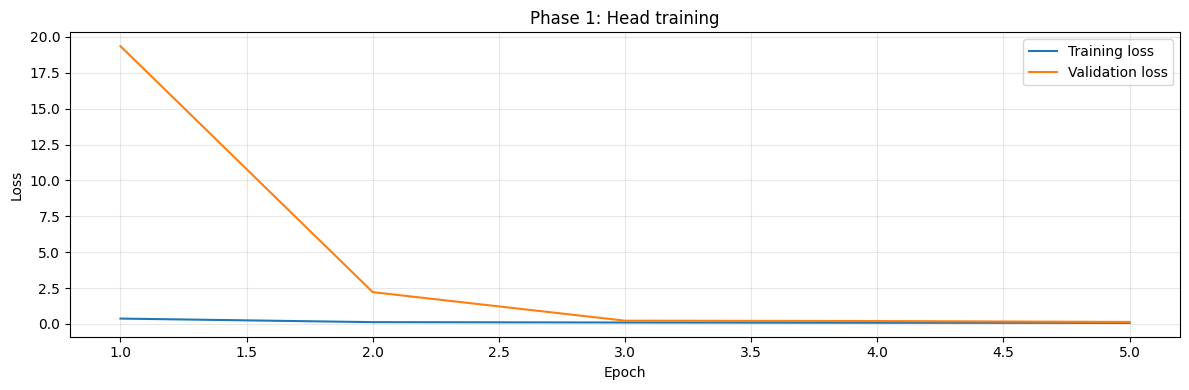

In [32]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 1, figsize=(12, 4))

for ax, title, history in [
    (axes, "Phase 1: Head training", head_history),
    # (axes[1], "Phase 2: Full-model fine-tuning", ft_history),
]:
    epochs = range(1, len(history.history["loss"]) + 1)

    ax.plot(epochs, history.history["loss"], label="Training loss")
    ax.plot(epochs, history.history["val_loss"], label="Validation loss")

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
model.load_weights(head_path)
head_val = model.evaluate(sequences["validation"],return_dict=True,verbose=0)["iou"]

### Phase 2 Model Training \<Full Model\>

In [34]:
backbone.trainable = True
model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),loss=bce_dice_loss,metrics=make_metrics())

In [35]:
ft_path = model_dir/"deeplab/fine_tune_best.weights.h5"
ft_history = model.fit(sequences["train"],validation_data=sequences["validation"],
                       epochs=FINE_TUNE_EPOCHS,callbacks=callbacks(ft_path))

Epoch 1/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 250s 4s/step - dice_coefficient: 0.9673 - iou: 0.9370 - loss: 0.0768 - precision: 0.9694 - recall: 0.9656 - val_dice_coefficient: 0.9621 - val_iou: 0.9265 - val_loss: 0.0863 - val_precision: 0.9570 - val_recall: 0.9668 - learning_rate: 1.0000e-04
Epoch 2/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - dice_coefficient: 0.9712 - iou: 0.9451 - loss: 0.0683 - precision: 0.9722 - recall: 0.9713 - val_dice_coefficient: 0.9679 - val_iou: 0.9377 - val_loss: 0.0737 - val_precision: 0.9733 - val_recall: 0.9625 - learning_rate: 1.0000e-04
Epoch 3/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - dice_coefficient: 0.9733 - iou: 0.9485 - loss: 0.0627 - precision: 0.9753 - recall: 0.9718 - val_dice_coefficient: 0.9685 - val_iou: 0.9393 - val_loss: 0.0710 - val_precision: 0.9792 - val_recall: 0.9584 - learning_rate: 1.0000e-04
Epoch 4/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - dice_coefficient: 0.9751 - iou: 0.9519 - loss: 0.0582 - precision: 0.9766 - recall: 0.9740 - va

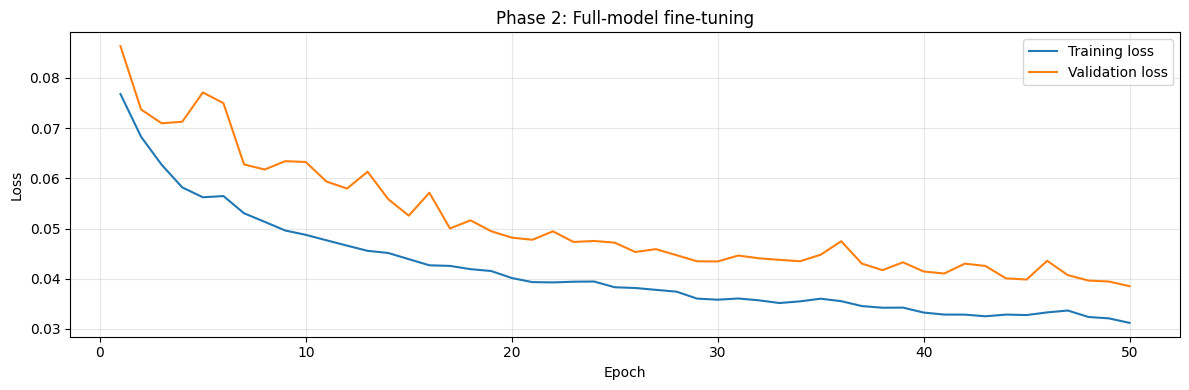

In [36]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 1, figsize=(12, 4))

for ax, title, history in [
    # (axes[0], "Phase 1: Head training", head_history),
    (axes, "Phase 2: Full-model fine-tuning", ft_history),
]:
    epochs = range(1, len(history.history["loss"]) + 1)

    ax.plot(epochs, history.history["loss"], label="Training loss")
    ax.plot(epochs, history.history["val_loss"], label="Validation loss")

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [37]:
model.load_weights(ft_path)

In [38]:
ft_val = model.evaluate(sequences["validation"],return_dict=True,verbose=0)["iou"]
if head_val > ft_val:
    model.load_weights(head_path)
    print("Selected head-phase checkpoint")
else: print("Selected fine-tuned checkpoint")

Selected fine-tuned checkpoint


## 3. Choose the threshold on validation, then evaluate test

The comparison below reports mean per-image scores on the same held-out tiles. NDWI=0 is a simple, fixed baseline. These results depend on labeled tiles and don't establish event prediction.


In [39]:
def ground_truth(dataset): return np.stack([dataset[i][1] for i in range(len(dataset))])

In [40]:
val_prob = model.predict(sequences["validation"],verbose=0)
val_gt = ground_truth(datasets["validation"])

In [41]:
### Best Threshold Tuning
thresholds = np.linspace(.2,.8,13)
mean_iou = [np.mean([compute_metrics(p[...,0]>=t,g[...,0])["IoU"]
                     for p,g in zip(val_prob,val_gt)]) for t in thresholds]

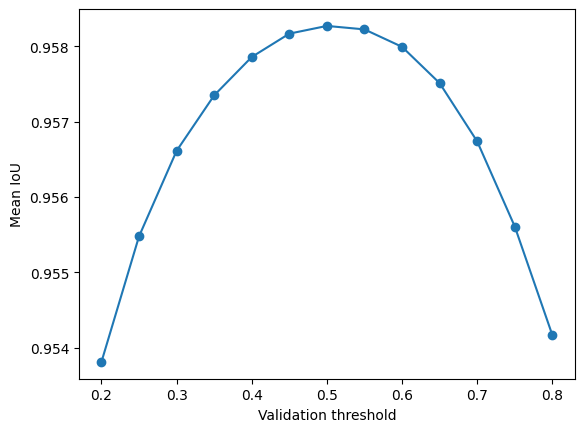

In [42]:
plt.plot(thresholds,mean_iou,"o-");plt.xlabel("Validation threshold");plt.ylabel("Mean IoU");plt.show()

In [43]:
best_threshold = float(thresholds[int(np.argmax(mean_iou))])
test_prob = model.predict(sequences["test"],verbose=0)
test_gt = ground_truth(datasets["test"])

In [44]:
rows = []
for i,(p,g) in enumerate(zip(test_prob,test_gt)):
    image = datasets["test"][i][0]
    for method,mask in [("DeepLab",p[...,0]>=best_threshold),("NDWI zero",compute_ndwi(image)>0)]:
        rows.append({"filename":splits["test"][0][i].name,"method":method,**compute_metrics(mask,g[...,0])})

In [45]:
evaluation = pd.DataFrame(rows)
display(evaluation.groupby("method")[["IoU","Precision","Recall","F1"]].mean())
evaluation.to_csv(model_dir/"segmentation_test_metrics.csv",index=False)

,IoU,Precision,Recall,F1
method,,,,
DeepLab,0.964166,0.982133,0.980990,0.981503
NDWI zero,0.729235,0.750880,0.971193,0.825205


## 4. Save, reload and upload

The companion metadata carries the chosen threshold and the model hash. Notebook 02 checks the model shape; notebook 03 refuses to reuse an area baseline built with different weights/settings. If you retrain after collecting time series, set a fresh `work_dir` in the shared configuration.


In [46]:
model.save(f"{model_dir}/deeplab/final_model.keras")

In [47]:
print("threshold: ", best_threshold, "input_bands: ",'["B8","B4","B3"]',
      "input_range: ","[0,255]", "image_size: ",400, "tensorflow_version: ", tf.__version__,"test_rows: ", len(test_gt), sep='\n')

threshold: 
0.5
input_bands: 
["B8","B4","B3"]
input_range: 
[0,255]
image_size: 
400
tensorflow_version: 
2.21.0
test_rows: 
62


In [48]:
### Load model for final Test inference
reloaded_model = tf.keras.models.load_model(f"{model_dir}/deeplab/final_model.keras", compile=False)
if tuple(model.input_shape[1:]) != (400, 400, 3) or tuple(model.output_shape[1:]) != (400, 400, 1):
  raise ValueError("Expected the supplied 400x400, 3-input-band, 1-output DeepLab model")

In [49]:
np.testing.assert_allclose(model(x[:1],training=False).numpy(),reloaded_model(x[:1],training=False).numpy(),rtol=1e-4,atol=1e-5)
# print("Save/reload check passed:",cfg.deeplab_path)

In [50]:
# UPLOAD_TO_S3 = True
# if UPLOAD_TO_S3:
#     from glofwatch.aws import put_file
#     for path in [cfg.deeplab_path,cfg.deeplab_path.with_suffix(".metadata.json"),
#                  model_dir/"segmentation_split.csv",model_dir/"segmentation_test_metrics.csv"]:
#         print(put_file(cfg,path,cfg.s3_prefix+"/models/deeplab/"+path.name))
# else: print("Kept artifacts locally; set UPLOAD_TO_S3=True when S3 is configured")
